In [14]:
# First, we need to read the updated dataset to prepare it for the machine learning model
# and subsequent SHAP analysis.
import pandas as pd

# Load the updated IoT dataset
dataset_path = '/content/iot_dataset_synthetic_updated_A.csv'
iot_dataset_updated = pd.read_csv(dataset_path)

# Display the first few rows to ensure it's loaded correctly
iot_dataset_updated.head()


,Timestamp,Smart Energy Consumption (kWh),Grid Frequency (Hz),Grid Voltage (V),Air Quality Index,Noise Level (dB),Latitude,Longitude,Solar Irradiance (W/m²),Wind Speed (m/s),Indoor Temperature (C),Humidity (%),Renewable Energy Source (%),Energy Demand Forecast (kWh)
0,2022-01-01 00:00:00,3.745401,49.873641,234.599966,332,72.038254,50.995111,-177.368174,319.952573,3.776546,22.513482,70.927945,80.566547,8.358536
1,2022-01-01 01:00:00,9.507143,49.832912,223.690240,90,47.749388,-4.997584,-43.679644,993.527277,5.565528,19.268346,67.352523,98.481722,10.941839
2,2022-01-01 02:00:00,7.319939,49.676154,226.932794,165,40.426256,9.118052,96.233500,209.334135,7.617355,24.453758,69.284644,86.149165,16.218032
3,2022-01-01 03:00:00,5.986585,50.107267,233.265613,160,56.224354,68.329256,-18.174293,872.625012,6.242967,24.334587,79.818585,78.678097,7.306361
4,2022-01-01 04:00:00,1.560186,49.976624,229.641787,5,104.204636,-1.245483,25.481863,732.337138,24.184555,24.740877,38.536466,53.120125,15.162867


In [15]:
pip install shap eli5


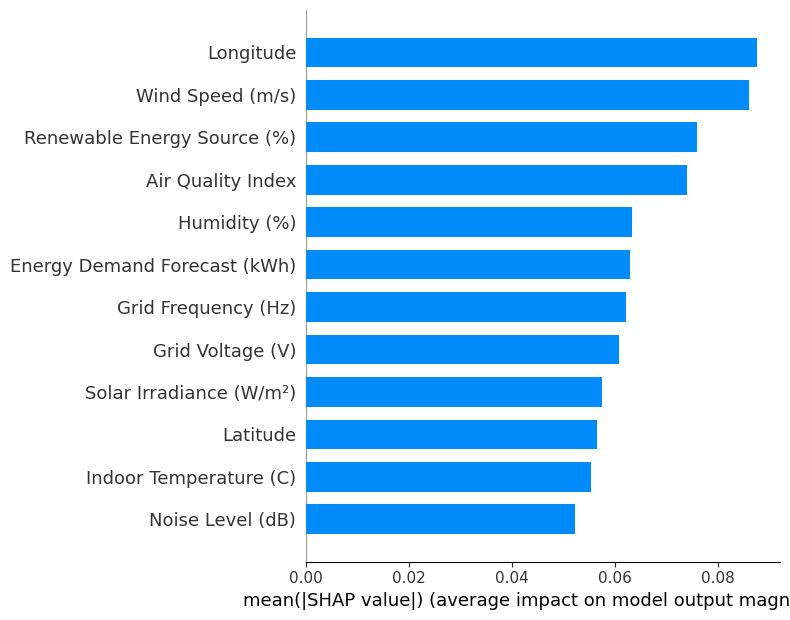

Weight,Feature
0.0050 ± 0.0061,Longitude
0.0049 ± 0.0078,Grid Voltage (V)
0.0042 ± 0.0076,Solar Irradiance (W/m²)
0.0038 ± 0.0041,Noise Level (dB)
0.0029 ± 0.0071,Wind Speed (m/s)
0.0018 ± 0.0053,Grid Frequency (Hz)
0.0010 ± 0.0074,Energy Demand Forecast (kWh)
0.0010 ± 0.0092,Air Quality Index
0.0008 ± 0.0046,Latitude
-0.0001 ± 0.0032,Humidity (%)


In [17]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
import shap
import eli5
from eli5.sklearn import PermutationImportance
import pandas as pd



iot_dataset_updated = pd.read_csv('/content/iot_dataset_synthetic_updated_A.csv')  # Adjust the path as necessary
X = iot_dataset_updated.drop(['Timestamp', 'Smart Energy Consumption (kWh)'], axis=1)
y = iot_dataset_updated['Smart Energy Consumption (kWh)']

# Assuming 'X' and 'y' are features and target variable
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = RandomForestRegressor(n_estimators=100, random_state=42).fit(X_train, y_train)

# SHAP Explainer
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

# For SHAP
# import shap  # Uncomment this after ensuring shap is installed
# explainer = shap.TreeExplainer(model)
# shap_values = explainer.shap_values(X_test)
# shap.summary_plot(shap_values, X_test, plot_type="bar")


# Visualization with SHAP
shap.summary_plot(shap_values, X_test, plot_type="bar")

# Feature Importance with ELI5
perm = PermutationImportance(model, random_state=42).fit(X_test, y_test)
eli5.show_weights(perm, feature_names = X_test.columns.tolist())


In [18]:
import numpy as np

# Calculate mean absolute SHAP values for each feature
mean_shap_values = np.abs(shap_values).mean(axis=0)

# Create a DataFrame for better visualization
features_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Mean Absolute SHAP Value': mean_shap_values
}).sort_values(by='Mean Absolute SHAP Value', ascending=False)

print(features_importance)


                         Feature  Mean Absolute SHAP Value
5                      Longitude                  0.087620
7               Wind Speed (m/s)                  0.086053
10   Renewable Energy Source (%)                  0.075837
2              Air Quality Index                  0.073877
9                   Humidity (%)                  0.063368
11  Energy Demand Forecast (kWh)                  0.062953
0            Grid Frequency (Hz)                  0.062118
1               Grid Voltage (V)                  0.060772
6        Solar Irradiance (W/m²)                  0.057365
4                       Latitude                  0.056421
8         Indoor Temperature (C)                  0.055359
3               Noise Level (dB)                  0.052296


Mean Squared Error: 1.3900244576153266e-07


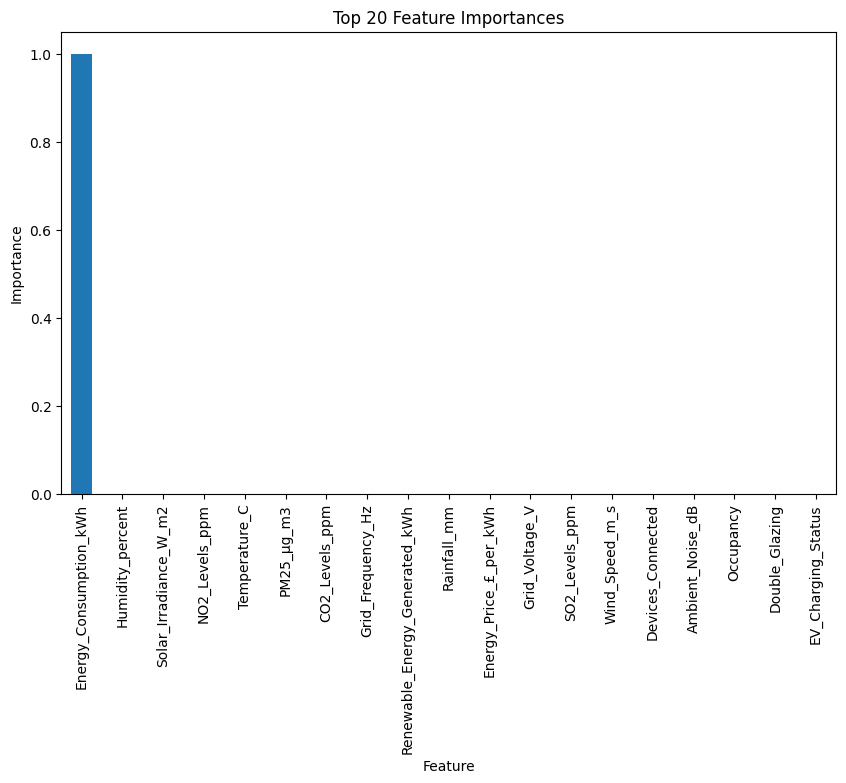

Energy_Consumption_kWh            0.999865
Humidity_percent                  0.000022
Solar_Irradiance_W_m2             0.000020
NO2_Levels_ppm                    0.000012
Temperature_C                     0.000010
PM25_µg_m3                        0.000010
CO2_Levels_ppm                    0.000009
Grid_Frequency_Hz                 0.000008
Renewable_Energy_Generated_kWh    0.000007
Rainfall_mm                       0.000007
dtype: float64

In [19]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt

# Assuming 'synthetic_iot_data' is our DataFrame and is already loaded

synthetic_iot_data = pd.read_csv('/content/synthetic_iot_data_B.csv')


# Prepare the data
X = synthetic_iot_data.drop(['Timestamp', 'Insulation_Quality'], axis=1, errors='ignore')  # errors='ignore' allows us to skip non-existing columns
y = synthetic_iot_data['Energy_Consumption_kWh']  # Target variable for feature importance

# Convert categorical data to numeric for model training
X = pd.get_dummies(X)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Initialize and fit the RandomForestRegressor
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# Predict on the test set
y_pred = rf.predict(X_test)

# Calculate the mean squared error
mse = mean_squared_error(y_test, y_pred)
print(f"Mean Squared Error: {mse}")

# Get feature importances
feature_importances = rf.feature_importances_

# Create a pandas series to visualize the feature importances
features_series = pd.Series(feature_importances, index=X.columns).sort_values(ascending=False)

# Plot the top 10 features
plt.figure(figsize=(10, 6))
features_series[:20].plot(kind='bar')
plt.title('Top 20 Feature Importances')
plt.ylabel('Importance')
plt.xlabel('Feature')
plt.show()

features_series[:10]


In [20]:
from sklearn.ensemble import IsolationForest
import pandas as pd

# Ensure 'synthetic_iot_data' is a DataFrame and features are correctly named
features = ['Energy_Consumption_kWh', 'CO2_Levels_ppm']
X = synthetic_iot_data[features]

# Initialize the Isolation Forest model
model = IsolationForest(n_estimators=100, contamination=0.01)

# Fit the model using a DataFrame with named columns
model.fit(X)

# Predict anomalies using the same DataFrame format
synthetic_iot_data['anomaly'] = model.predict(X)

# Filter and analyze anomalies
anomalies = synthetic_iot_data[synthetic_iot_data['anomaly'] == -1]
print(anomalies)


X does not have valid feature names, but IsolationForest was fitted with feature names


                Timestamp  Energy_Consumption_kWh  Grid_Frequency_Hz  \
74    2021-01-01 01:14:00                0.069013          50.091777   
209   2021-01-01 03:29:00                0.392637          49.931131   
262   2021-01-01 04:22:00                0.037937          50.059109   
478   2021-01-01 07:58:00                0.353944          50.190065   
668   2021-01-01 11:08:00                0.067452          50.006578   
...                   ...                     ...                ...   
8500  2021-01-06 21:40:00                0.325272          49.994565   
8726  2021-01-07 01:26:00                0.357889          49.908403   
9606  2021-01-07 16:06:00                0.059904          49.910207   
9770  2021-01-07 18:50:00                0.003880          49.882590   
9802  2021-01-07 19:22:00                0.315282          50.062881   

      Grid_Voltage_V  Temperature_C  Humidity_percent  Wind_Speed_m_s  \
74        237.873758      16.868734         49.376796        4

# Validation

In [21]:
# Print column names to verify
print(synthetic_iot_data_B.columns)
print(synthetic_external_data.columns)


Index(['Timestamp', 'Energy_Consumption_kWh', 'Grid_Frequency_Hz',
       'Grid_Voltage_V', 'Temperature_C', 'Humidity_percent', 'Wind_Speed_m_s',
       'Solar_Irradiance_W_m2', 'Rainfall_mm', 'CO2_Levels_ppm',
       'NO2_Levels_ppm', 'SO2_Levels_ppm', 'PM25_µg_m3', 'Ambient_Noise_dB',
       'Devices_Connected', 'Energy_Price_£_per_kWh', 'EV_Charging_Status',
       'Insulation_Quality', 'Double_Glazing', 'Occupancy',
       'Renewable_Energy_Generated_kWh'],
      dtype='object')
Index(['Timestamp', 'Temperature_C_External', 'Solar_Irradiance_W_m2_External',
       'Maintenance_Events', 'Special_Events'],
      dtype='object')


In [22]:
import numpy as np


# Generating dummy anomaly flags for demonstration purposes
# This is just for illustration; replace this with actual anomaly detection output
anomaly_flags = np.random.choice([-1, 1], size=len(synthetic_iot_data_B), p=[0.05, 0.95])


In [23]:
synthetic_iot_data_B['anomaly'] = anomaly_flags


In [24]:
import pandas as pd

# Load the datasets
synthetic_external_data = pd.read_csv('/content/synthetic_external_data.csv')
synthetic_iot_data_B = pd.read_csv('/content/synthetic_iot_data_B.csv')

# Ensure the 'Timestamp' column is in the correct datetime format for both datasets
synthetic_external_data['Timestamp'] = pd.to_datetime(synthetic_external_data['Timestamp'])
synthetic_iot_data_B['Timestamp'] = pd.to_datetime(synthetic_iot_data_B['Timestamp'])

# Merge the datasets on the 'Timestamp' column
merged_dataset = pd.merge(synthetic_iot_data_B, synthetic_external_data, on='Timestamp', how='inner')


In [29]:
print(merged_dataset.columns)

Index(['Timestamp', 'Energy_Consumption_kWh', 'Grid_Frequency_Hz',
       'Grid_Voltage_V', 'Temperature_C', 'Humidity_percent', 'Wind_Speed_m_s',
       'Solar_Irradiance_W_m2', 'Rainfall_mm', 'CO2_Levels_ppm',
       'NO2_Levels_ppm', 'SO2_Levels_ppm', 'PM25_µg_m3', 'Ambient_Noise_dB',
       'Devices_Connected', 'Energy_Price_£_per_kWh', 'EV_Charging_Status',
       'Insulation_Quality', 'Double_Glazing', 'Occupancy',
       'Renewable_Energy_Generated_kWh', 'Temperature_C_External',
       'Solar_Irradiance_W_m2_External', 'Maintenance_Events',
       'Special_Events'],
      dtype='object')


In [32]:
from sklearn.ensemble import IsolationForest

# Initialize the Isolation Forest model
model = IsolationForest(n_estimators=100, contamination=0.01, random_state=42)

# Selecting features for anomaly detection from the merged dataset
features_for_detection = ['Energy_Consumption_kWh', 'CO2_Levels_ppm']
X_detection = merged_dataset[features_for_detection]

# Fit the model and predict anomalies
model.fit(X_detection)
merged_dataset['anomaly'] = model.predict(X_detection)

print(merged_dataset.head())

X does not have valid feature names, but IsolationForest was fitted with feature names


            Timestamp  Energy_Consumption_kWh  Grid_Frequency_Hz  \
0 2021-01-01 00:00:00                0.224836          49.932151   
1 2021-01-01 00:01:00                0.193087          49.969450   
2 2021-01-01 00:02:00                0.232384          49.940262   
3 2021-01-01 00:03:00                0.276151          50.011042   
4 2021-01-01 00:04:00                0.188292          50.119718   

   Grid_Voltage_V  Temperature_C  Humidity_percent  Wind_Speed_m_s  \
0      241.741431      -9.805720         79.903753       13.451545   
1      241.416618      -0.549856         50.726066       11.292424   
2      235.317401       4.129716         72.322188        6.497295   
3      242.897921      11.496689         33.036155       24.931773   
4      232.549587      20.241623         57.841106       21.208939   

   Solar_Irradiance_W_m2  Rainfall_mm  CO2_Levels_ppm  ...  \
0             370.684579     1.980756      445.006867  ...   
1              81.031110     1.749168      492

In [33]:
# Filter for anomalies
anomalies_with_external_data = merged_dataset[merged_dataset['anomaly'] == -1]
print(anomalies_with_external_data.head())

              Timestamp  Energy_Consumption_kWh  Grid_Frequency_Hz  \
74  2021-01-01 01:14:00                0.069013          50.091777   
179 2021-01-01 02:59:00                0.336008          50.111834   
209 2021-01-01 03:29:00                0.392637          49.931131   
262 2021-01-01 04:22:00                0.037937          50.059109   
378 2021-01-01 06:18:00                0.309490          49.982819   

     Grid_Voltage_V  Temperature_C  Humidity_percent  Wind_Speed_m_s  \
74       237.873758      16.868734         49.376796        4.833109   
179      235.203396       7.500564         70.724752        6.020680   
209      232.352961       5.463459         49.145541       21.570098   
262      243.973392       8.776689         84.964965        8.023117   
378      247.762402       7.134414         69.061918       19.986093   

     Solar_Irradiance_W_m2  Rainfall_mm  CO2_Levels_ppm  ...  \
74              399.378920     5.356192      398.663009  ...   
179             71

In [34]:
# Replace 'column_names' with specific columns of interest
print(anomalies_with_external_data[['Timestamp', 'Energy_Consumption_kWh', 'CO2_Levels_ppm', 'Temperature_C_External', 'Solar_Irradiance_W_m2_External']].head())



              Timestamp  Energy_Consumption_kWh  CO2_Levels_ppm  \
74  2021-01-01 01:14:00                0.069013      398.663009   
179 2021-01-01 02:59:00                0.336008      477.806212   
209 2021-01-01 03:29:00                0.392637      428.842984   
262 2021-01-01 04:22:00                0.037937      474.845503   
378 2021-01-01 06:18:00                0.309490      390.420301   

     Temperature_C_External  Solar_Irradiance_W_m2_External  
74                 9.137147                             0.0  
179               -2.249581                             0.0  
209               -1.783839                             0.0  
262               -2.198320                             0.0  
378               11.289370                             0.0  


In [35]:
print(f"Number of anomalies detected: {len(anomalies_with_external_data)}")


Number of anomalies detected: 100


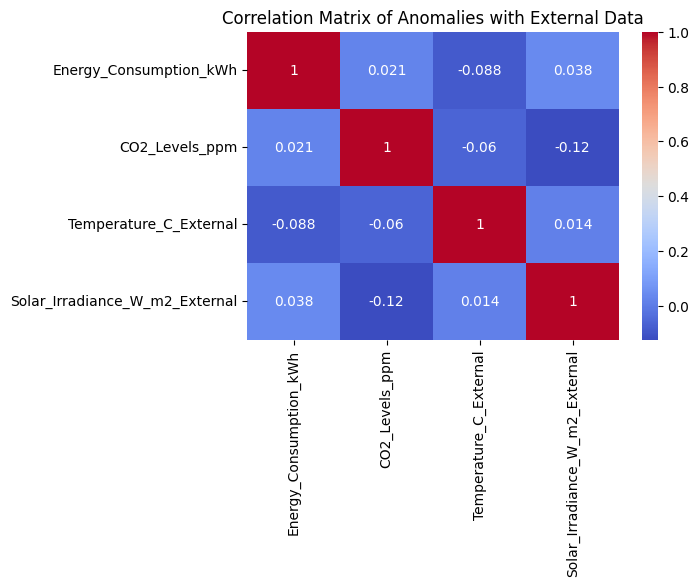

In [37]:
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate correlation matrix for the anomalies with external data
corr_matrix = anomalies_with_external_data[['Energy_Consumption_kWh', 'CO2_Levels_ppm', 'Temperature_C_External', 'Solar_Irradiance_W_m2_External']].corr()

# Plot the correlation matrix as a heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix of Anomalies with External Data')
plt.show()
